# Laboratorio 5B · Leer órdenes de trabajo con un transformer

Cada día llegan a **MantenIA**, la empresa ficticia de mantenimiento industrial del curso, decenas de órdenes de trabajo escritas a la carrera: «el motor no arranca», «gotea la válvula», «el sensor marca raro». Alguien debe enviar cada una al equipo que la atiende: **eléctrico, mecánico, fugas o instrumentación**. ¿Puede hacerlo una red neuronal con pocas órdenes etiquetadas?

Usted comparará tres **arquitecturas** con los mismos ejemplos: una **bolsa de palabras**, una **red recurrente** entrenada desde cero y un **transformer preentrenado**. Las pondrá a prueba con órdenes escritas con otras palabras y con **negaciones**, y terminará con un **LLM** que clasifica solo con una instrucción.

En este laboratorio usted:
* Clasificará órdenes de trabajo con tres arquitecturas y los mismos ejemplos etiquetados.
* Verá cuántos ejemplos necesita cada una.
* Las pondrá a prueba con sus propias órdenes, incluidas negaciones como «no hay fuga».
* Comparará con un LLM los aciertos, el costo por cada 1000 órdenes y la privacidad, y decidirá qué usaría MantenIA.

| | |
| :--- | :--- |
| **Resultados de aprendizaje** | RA6: explicar y aplicar redes neuronales y la arquitectura transformer. RA8, en el contrapunto: evaluar un LLM frente a otras técnicas por su validez y su costo. |
| **Tiempo** | 60 minutos en clase (secciones 0 a 8) y hasta 30 en casa (la 9.2, los análisis ✏️ y la 10). En clase, escriba cada análisis en una frase. La sección 9.1 es el punto de partida del TI-2. |
| **Modalidad** | En parejas. **No se escribe código:** se cambian números, órdenes y nombres de archivo en las celdas marcadas con ✏️. |
| **Antes de clase** | Ejecute `preparar.ipynb` en casa: descarga el transformer, 214 MB. |
| **Entrega** | Este notebook ejecutado y el archivo `resultados_5B.csv`, al inicio de la semana 4 del curso (sección 10). |

## Contenido

* [Antes de empezar](#0) · *en clase, 6 min*
* [1 - Las órdenes de MantenIA](#1) · *en clase, 4 min*
* [2 - La bolsa de palabras](#2) · *en clase, 5 min*
* [3 - La red recurrente, desde cero](#3) · *en clase, 4 min*
* [4 - El transformer preentrenado](#4) · *en clase, 8 min*
* [5 - ¿Cuántos ejemplos necesita cada una?](#5) · *en clase, 6 min*
* [6 - Póngalo a prueba](#6) · *en clase, 12 min*
* [7 - El contrapunto: un LLM con instrucciones](#7) · *en clase, 5 min*
* [8 - Comparar y decidir](#8) · *en clase, 8 min*
* [9 - Para casa: sus textos y el LLM otra vez](#9) · *para casa, 10 min; la 9.1, trabajo independiente TI-2*
* [10 - Entrega y criterios](#10) · *para casa, 5 min*
* [Conclusión](#conclusion) · [Referencias](#referencias)

<details>
<summary><b>💡 Otra forma de navegar: el panel Esquema de VS Code</b> (clic para desplegar)</summary>

VS Code lista todos los títulos de este notebook en el panel **Esquema** (*Outline*), dentro del Explorador de la barra lateral izquierda. Al hacer clic en un título, el notebook salta a esa sección.

</details>

<a id='0'></a>
## Antes de empezar

Ejecute las celdas **en orden**. Solo se editan las celdas marcadas con ✏️: en ellas se cambian números, órdenes entre comillas o nombres de archivo, nunca el resto del código.

<details>
<summary><b>Cómo usar este notebook en VS Code</b> (si lo necesita)</summary>

1. Con **Archivo › Abrir carpeta**, abra la carpeta del curso, la que contiene el entorno `.venv`.
2. Abra este notebook y, en **Seleccionar kernel** (arriba a la derecha), elija el entorno `.venv` del curso.
3. Ejecute cada celda con **Shift + Enter** o con el botón ▷ de su izquierda.
4. Para editar una celda de texto, como las de análisis, haga doble clic sobre ella; para verla de nuevo, **Shift + Enter**.
5. Si algo falla, lea el mensaje: los módulos de apoyo explican en español qué revisar, en una caja roja. Un `SyntaxError`, en inglés, quiere decir que algo de lo que escribió en la celda está mal formado: revise las comillas, las comas, los dos puntos y los corchetes. Si el problema persiste, use **Reiniciar** y luego **Ejecutar todo**.

</details>

<details>
<summary><b>Respaldo: trabajar en Google Colab</b> (por ejemplo, en un Mac con procesador Intel)</summary>

En un Mac con procesador Intel no hay `torch` para Python 3.13, y las redes no corren en VS Code. Use Colab:
1. Pida al docente el archivo `lab_5B_ordenes_de_trabajo.zip` y abra este notebook en [Colab](https://colab.research.google.com/) con **Archivo › Subir notebook**.
2. Suba el .zip a la carpeta `/content` en el panel **Archivos** de Colab.
3. Para usar la vía API, guarde su clave en los **Secrets** de Colab (el ícono de la llave), con el nombre `ANTHROPIC_API_KEY`. Sin clave, el notebook usa las respuestas grabadas.
4. Ejecute la celda siguiente: descomprime la carpeta, usa el `torch` que Colab ya trae y descarga el transformer la primera vez que se use.

</details>

<details>
<summary><b>Glosario breve</b>, por si una palabra no le resulta familiar</summary>

* **LLM:** un modelo de lenguaje grande, como Claude, Gemini o ChatGPT (sección 7).
* **Ejemplos etiquetados:** órdenes de las que ya se sabe el equipo; con ellas aprenden las arquitecturas.
* **Pesos:** los números que una red aprende con los ejemplos, como en el Laboratorio 5A.
* **Vocabulario:** las palabras distintas que aparecen en los ejemplos.
* **Vector:** una lista de números. Las tres arquitecturas convierten cada orden en un vector.
* **Similitud:** un puntaje de parecido entre dos vectores, de −1 a 1; cuanto más alto, más parecidos. Es el coseno del ángulo entre ellos, como en CLIP en la Sesión 4.
* **Preentrenado:** un modelo que ya aprendió con muchísimo texto antes de usarlo aquí. **Congelado:** sus pesos no cambian en este laboratorio.
* **Codificador:** un transformer que lee un texto completo y lo resume en vectores; no genera texto. **Decodificador:** un transformer que genera texto, token por token; los LLMs lo son.
* **Instrucción de sistema:** el texto fijo que el LLM recibe antes de cada orden y que le dice cuál es su tarea.
* **Explicabilidad:** qué tanto se puede mostrar por qué un modelo decidió lo que decidió.
* **Token:** la unidad en que un LLM lee y cobra: un pedazo de palabra.
* **Matriz de confusión:** la tabla que cruza el equipo real de cada orden con el asignado.
* **Semilla:** el número con que arranca el azar del computador; fijarla hace que el entrenamiento se repita igual.
* **CPU:** el procesador general del computador. Las tres arquitecturas corren en él, sin tarjeta gráfica.

</details>

* Ejecute la siguiente celda para preparar el entorno: comprueba Python e instala lo que falte de `requirements.txt`. Si ya ejecutó `preparar.ipynb`, no descarga nada.

In [ ]:
# Preparar el entorno: comprobar Python e instalar lo que falte de requirements.txt
import os, pathlib, sys, zipfile
if "google.colab" in sys.modules and not pathlib.Path("entorno.py").exists():
    # Respaldo en Colab: descomprimir la carpeta del laboratorio que usted subió como .zip
    zipfile.ZipFile("/content/lab_5B_ordenes_de_trabajo.zip").extractall("/content")
    os.chdir("/content/lab_5B_ordenes_de_trabajo")
import entorno
entorno.preparar(en_colab_aceptar=("torch", "transformers"))

El laboratorio usa cuatro módulos de apoyo, en la misma carpeta del notebook.

<details>
<summary><b>Qué hace cada módulo</b> (clic para desplegar)</summary>

* `ordenes` lee las órdenes, entrena y prueba las tres arquitecturas, consulta al LLM, compara y guarda los resultados.
* `graficas` dibuja las matrices de confusión, los errores y los aciertos según la cantidad de ejemplos.
* `cliente_llm` envía cada orden al LLM por la vía disponible y registra los tokens, el tiempo y el costo de cada llamada.
* `presentacion` muestra tablas y mensajes en cajas de color.

</details>

* Ejecute la siguiente celda para importar los módulos.

In [ ]:
# Importar los módulos de apoyo del laboratorio
import ordenes as o
import presentacion as p
import cliente_llm

<a id='0-1'></a>
### 0.1 - El transformer que corre en su computador

El transformer es un **modelo abierto**: sus pesos se descargan una vez y corren en su computador, sin internet y sin costo por orden.

* Ejecute la siguiente celda para comprobar que esté descargado.

In [ ]:
# Comprobar que el transformer esté descargado y que torch y transformers funcionen
modelo_listo = o.comprobar_modelo()

<a id='0-2'></a>
### 0.2 - Elegir el LLM

El LLM se usa en las secciones 7 y 9. En clase, deje `None`: el notebook elige la primera vía disponible y dice cuál usa.

<details>
<summary><b>Las tres vías</b> (clic para desplegar)</summary>

* **API:** con una clave en un archivo `.env` de la carpeta del curso, que nunca se imprime. El modelo de Anthropic por defecto es Claude Haiku 5.5, sin modo de razonamiento: la corrida de la clase cuesta menos de un centavo de dólar.
* **Local:** con Ollama y un modelo de texto, como `qwen3:4b-instruct`. Nada sale de su computador.
* **Grabado:** respuestas reales de Claude Haiku 5.5, sin llamadas ni clave.

</details>

* Ejecute la siguiente celda para ver las vías disponibles y crear el cliente del LLM.

In [ ]:
# ✏️ Configuración del LLM: deje None para que el notebook elija la primera vía disponible
PROVEEDOR = None    # "anthropic", "openai", "gemini", "ollama" o "grabado"
MODELO_LLM = None   # None usa el LLM por defecto del proveedor
p.mostrar_tabla(cliente_llm.estado_proveedores(), titulo="Vías de acceso a un LLM en este computador")
llm = cliente_llm.ClienteLLM(proveedor=PROVEEDOR, modelo=MODELO_LLM, max_llamadas=300)

<a id='1'></a>
## 1 - Las órdenes de MantenIA

Las órdenes son ficticias, escritas como las escribiría el personal de una planta: frases cortas, abreviaturas (VFD, PLC, Mtto), jerga y algún error de digitación. Cada equipo atiende:

| Equipo | Qué atiende |
| :--- | :--- |
| eléctrico | La energía y los equipos eléctricos: motores, tableros, breakers, contactores, variadores, cables e iluminación |
| mecánico | Las piezas en movimiento: rodamientos, ejes, correas, cadenas, engranajes, acoples y poleas; ruidos, vibración, desgaste |
| fugas | Los escapes de líquidos, aire, vapor o gas: goteos, empaques, sellos, mangueras y tuberías |
| instrumentación | Los sensores, medidores y transmisores, sus lecturas y su calibración, las señales al PLC y las alarmas |

El archivo `datos/ordenes.csv`, que se abre en Excel, tiene tres conjuntos:
* **entrenamiento:** 50 órdenes por equipo. Con «10 ejemplos por equipo» se usan las 10 primeras de cada equipo del archivo.
* **prueba:** 12 órdenes por equipo, **escritas con otras palabras** que las de entrenamiento. Con ellas se miden los aciertos. Al azar, se acertarían 12 de 48.
* **trampa** y **control:** 8 órdenes con negaciones y palabras engañosas, y 2 de control que dicen lo mismo sin trampa, para la sección 6.

* Ejecute la siguiente celda para leer las órdenes.

In [ ]:
# Leer las órdenes de MantenIA: dos ejemplos de cada equipo y cuántas hay en cada conjunto
ordenes = o.cargar_ordenes()

Las tres arquitecturas reciben las mismas órdenes y terminan igual: en **la red del Laboratorio 5A**, un perceptrón multicapa con dos capas ocultas de 64 neuronas y dropout, ahora con una salida por equipo. Gana el equipo con la salida más alta. Lo que cambia es cómo cada una convierte el texto en números.

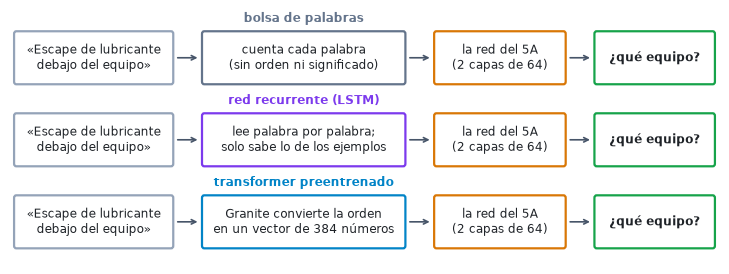

<a id='2'></a>
## 2 - La bolsa de palabras

Una red recibe números, no palabras. La forma más simple de convertir una orden en números es la **bolsa de palabras**: se arma un **vocabulario** con las palabras de los ejemplos, y cada orden se vuelve una lista que cuenta cuántas veces aparece cada una. Pierde el orden: «no hay fuga» y «fuga, no hay» quedan iguales. Y pierde el significado: «fuga» y «escape» son columnas distintas, sin relación. Una palabra que no está en los ejemplos no cuenta.

**Desglose del experimento.** La celda entrena la bolsa de palabras con **10 ejemplos por equipo** (40 órdenes), clasifica las 48 de prueba y muestra la matriz de confusión y los errores. Las secciones 3 y 4 usan los mismos ejemplos.

* Ejecute la siguiente celda para entrenar y probar la bolsa de palabras.

In [ ]:
# La bolsa de palabras con la red del 5A, entrenada con 10 ejemplos por equipo
bolsa = o.clasificar(ordenes, "bolsa", ejemplos=10)

**Análisis.** En la tabla de errores, la última columna dice qué palabras de la orden aparecen en los 40 ejemplos. Si dice «ninguna», o solo «de» y «el», la bolsa de palabras no tiene con qué decidir, y la red elige casi al azar.

<a id='3'></a>
## 3 - La red recurrente, desde cero

Una **red recurrente** lee la orden palabra por palabra, en orden, y lleva una memoria de lo que ha leído. La **LSTM** (Hochreiter y Schmidhuber, 1997) es la más conocida. Cada palabra se convierte en un vector de 32 números que la red aprende **desde cero**, con los mismos 40 ejemplos. A diferencia de la bolsa, tiene en cuenta el orden; pero solo conoce las palabras que vio en los ejemplos, y las demás le llegan como «desconocida».

* Ejecute la siguiente celda para entrenar y probar la red recurrente con los mismos 10 ejemplos por equipo.

In [ ]:
# La red recurrente (LSTM) entrenada desde cero, con los mismos 10 ejemplos por equipo
lstm = o.clasificar(ordenes, "lstm", ejemplos=10)

**Análisis.** Compare sus aciertos con los de la bolsa y con el azar (12 de 48). Una red recurrente tiene miles de pesos que aprender, y 40 ejemplos le dan poca evidencia. Si una columna de la matriz concentra las órdenes, la red aprendió a decir casi siempre el mismo equipo.

<a id='4'></a>
## 4 - El transformer preentrenado

El transformer es **Granite Embedding 107M multilingüe**, de IBM (2025): un **codificador** de la familia de BERT (Google, 2019), con 6 capas de atención, **preentrenado** con muchísimo texto en muchos idiomas, el español incluido. Convierte cada orden en un **vector** de 384 números que resume su significado: la atención ajusta cada palabra a su contexto («banco» no es lo mismo en «el banco cobró» que en «banco de pruebas»), y dos órdenes que dicen lo mismo con otras palabras quedan cerca. Se usa **congelado**, sin ajustarlo, con la misma red del 5A encima.

* Ejecute la siguiente celda para probar el transformer con los mismos 10 ejemplos por equipo. La primera vez, cargar el modelo toma unos segundos.

In [ ]:
# El transformer preentrenado (Granite, congelado) con la red del 5A encima, con los mismos 10 ejemplos por equipo
transformer = o.clasificar(ordenes, "transformer", ejemplos=10)

¿Por qué acierta con palabras que no vio? La celda siguiente busca las órdenes de entrenamiento más parecidas a «Escape de lubricante debajo del equipo», con su similitud y las palabras que comparten.

* Ejecute la siguiente celda para ver las órdenes más parecidas.

In [ ]:
# Las órdenes de entrenamiento más parecidas a una orden de prueba, según el transformer
o.mas_parecidas(ordenes, "Escape de lubricante debajo del equipo", ejemplos=10)

**Análisis.** Si las órdenes más parecidas son de fugas y casi no comparten palabras con la de prueba, el transformer usa lo que aprendió al preentrenarse: que «escape» y «fuga», o «lubricante» y «aceite», hablan de lo mismo. Las otras dos arquitecturas no pueden aprenderlo con 40 ejemplos.

**✏️ Su análisis (secciones 2 a 4).** *En clase, responda solo la primera pregunta, en una frase; la otra, en casa. ¿Cuántas órdenes de prueba acertó cada arquitectura con 10 ejemplos por equipo? Elija un error de la bolsa de palabras: ¿por qué falló, y por qué el transformer acertó o también falló?*

*Escriba aquí.*

<a id='5'></a>
## 5 - ¿Cuántos ejemplos necesita cada una?

Etiquetar órdenes cuesta: alguien debe leer cada una y anotar el equipo. Una arquitectura que acierta con pocos ejemplos ahorra ese trabajo.

**Desglose del experimento.** La celda entrena las tres arquitecturas con cada cantidad de ejemplos por equipo de la lista `CANTIDADES` y dibuja sus aciertos en las 48 órdenes de prueba. La lista trae 10, que ya corrió; agregue 3 y 30, separados por comas: `[3, 10, 30]`. El máximo es 50.

* Agregue 3 y 30 a `CANTIDADES` y ejecute la celda.

In [ ]:
# ✏️ Las cantidades de ejemplos por equipo, separadas por comas (10 ya está, agregue 3 y 30)
CANTIDADES = [10]
cantidades = o.comparar_cantidades(ordenes, CANTIDADES)

**Análisis.** Lea dónde empieza cada línea, con pocos ejemplos, y dónde termina. La que empieza alta trae conocimiento previo: el preentrenamiento. Las que suben con más ejemplos aprenden solo de lo que se les muestra. Si dos líneas se acercan con 30 ejemplos, pregúntese cuánto cuesta etiquetar esas órdenes en MantenIA.

<a id='6'></a>
## 6 - Póngalo a prueba

Las órdenes de prueba usan otras palabras, pero dicen las cosas de frente. Las **trampas** no: «No es una fuga: el manómetro marca mal» habla de fuga y es de instrumentación.

**Desglose del experimento.** La tabla muestra las trampas y los controles del archivo y sus órdenes de `MIS_ORDENES`, clasificadas por las tres arquitecturas con 10 ejemplos por equipo. Verde: acierta; rojo: no. En clase, escriba dos órdenes: una con una negación y una de su experiencia; en casa puede agregar más.

Cada orden va entre comillas, luego dos puntos y el equipo entre comillas, y una coma al final: `"Se sale el aceite por la tapa": "fugas",`. Borre el `#` de la línea de ejemplo, cambie su texto y su equipo por los de su orden, y escriba la segunda orden en la línea siguiente, con el mismo formato.

<details>
<summary><b>Pista</b></summary>

El equipo se escribe como en la tabla de la sección 1; las tildes y las mayúsculas no importan. Si aparece `SyntaxError`, falta una comilla, los dos puntos o una coma. Python señala el punto donde se dio cuenta, que suele ser el final de la línea, aunque la comilla que falta esté antes: revise la línea completa y compárela con el ejemplo.

</details>

* Escriba dos órdenes en `MIS_ORDENES` y ejecute la celda.

In [ ]:
# ✏️ Sus órdenes: el texto entre comillas, dos puntos y el equipo que debería atenderla
MIS_ORDENES = {
    # "Escriba aquí su orden": "fugas",
}
pruebas = o.poner_a_prueba(ordenes, MIS_ORDENES, ejemplos=10)

¿Cuánto cambia el vector de una orden si se le agrega un «no»? La celda siguiente compara «Hay fuga de aceite en la bomba 3» con su negación, con una orden que dice lo mismo con otras palabras y con otra de otro equipo.

* Ejecute la siguiente celda para ver las similitudes.

In [ ]:
# La similitud de una orden con su negación, con otras palabras y con otro equipo
o.similitudes(["Hay fuga de aceite en la bomba 3", "No hay fuga de aceite en la bomba 3",
               "Escape de lubricante en la bomba 3", "El rodamiento de la bomba 3 hace ruido"])

**Análisis.** Compare filas, no valores sueltos: con el transformer casi cualquier par de órdenes pasa de 0,6. Si la negación da casi 1, el transformer ve «hay fuga» y «no hay fuga» como la misma orden: resume la frase en un solo vector, donde «no» pesa poco, y se entrenó para reconocer frases del mismo tema. La bolsa de palabras también: ninguna entiende la negación. La diferencia está en la fila de otras palabras: el transformer captura el tema, no si se afirma o se niega. Y si en las trampas la bolsa acierta tantas como el transformer, es porque muchas traen una palabra que delata el equipo, como «manómetro».

**✏️ Su análisis (secciones 5 y 6).** *En clase, responda solo la primera pregunta, en una frase; las demás, en casa. ¿Cuántos ejemplos por equipo necesitó la bolsa de palabras para acercarse a lo que el transformer logró con 3? ¿Qué trampas u órdenes suyas falló el transformer, y qué tienen en común? ¿Cómo verificaría MantenIA una orden con una negación antes de despacharla?*

*Escriba aquí.*

<a id='7'></a>
## 7 - El contrapunto: un LLM con instrucciones

Un **LLM** es un transformer mucho más grande, un decodificador, preentrenado y luego ajustado para seguir instrucciones. Aquí no recibe ejemplos etiquetados: solo una instrucción que nombra los cuatro equipos con una línea de definición cada uno. Frente a las arquitecturas anteriores, **cobra por token**, **tarda más** y, por la vía API, **cada orden sale de su computador** hacia el proveedor.

**Desglose del experimento.** El LLM recibe las 48 órdenes de prueba y las 10 de la sección 6 (trampas y controles), una por llamada, con la misma instrucción en todas. Si la respuesta no es exactamente un equipo, cuenta como **«sin respuesta válida»**, sin adivinar. Con la API toma alrededor de un minuto; con las respuestas grabadas, un instante.

* Ejecute la siguiente celda para ver la instrucción.

In [ ]:
# La instrucción que recibe el LLM con cada orden
o.mostrar_instruccion(ordenes)

* Ejecute la siguiente celda para clasificar las órdenes con el LLM.

In [ ]:
# El LLM clasifica las 48 órdenes de prueba y las 10 trampas y controles, solo con la instrucción
llm_ordenes = o.clasificar_llm(llm, ordenes)

**Análisis.** Lea la matriz como las anteriores, y después la caja de costo. Compare las trampas con las de la sección 6: si el LLM las acierta, lee la negación que el codificador resumía mal. Pero un LLM también se equivoca, y puede responder distinto en otra corrida (sección 9.2): su resultado se verifica igual que los demás.

<a id='8'></a>
## 8 - Comparar y decidir

La guía de decisión del curso, que se presenta en la charla de cierre, usa cinco criterios: los datos, los ejemplos etiquetados, el costo por consulta, la explicabilidad y si los datos pueden salir de la organización. Un **LLM vía API** sirve casi sin ejemplos, pero cobra por token y los datos salen; un **modelo preentrenado pequeño**, en el propio computador, clasifica con decenas de ejemplos, casi sin costo y sin sacar los datos. Piense también en lo que la tabla no dice: el LLM necesita internet y depende de un proveedor, y las órdenes reales pueden traer nombres de personas.

**Desglose del experimento.** La tabla reúne las tres arquitecturas, entrenadas con `EJEMPLOS_ELEGIDOS` por equipo, y el LLM. `EJEMPLOS_ELEGIDOS` es una decisión de negocio, no el mejor resultado: cada orden etiquetada es tiempo de una persona que la lee y anota el equipo. Escriba una cantidad realista para MantenIA, de las que probó en la sección 5, y los nombres de la pareja. La celda guarda además `resultados_5B.csv`, con las columnas comunes del curso.

* Escriba los ejemplos elegidos y los nombres de la pareja, y ejecute la celda.

In [ ]:
# ✏️ Cuántos ejemplos por equipo podría etiquetar MantenIA, y los nombres de la pareja para el CSV
EJEMPLOS_ELEGIDOS = 10
PAREJA = "Nombre 1 y Nombre 2"
o.tabla_comparacion(ordenes, EJEMPLOS_ELEGIDOS, llm_ordenes)
ruta_csv = o.exportar_csv(PAREJA)

**✏️ Su análisis (secciones 7 y 8).** *En clase, responda solo la primera pregunta, en una frase; las demás, en casa. ¿Qué usaría MantenIA para despachar sus órdenes, y por qué, con las cifras de la tabla? ¿Cuánto costaría el LLM con 200 órdenes al día durante un año? ¿Qué verificación agregaría, sea cual sea la elección?*

*Escriba aquí.*

<a id='9'></a>
## 9 - Para casa: sus textos y el LLM otra vez

<a id='9-1'></a>
### 9.1 - Sus textos (trabajo independiente TI-2)

El notebook acepta otros textos y otras clases sin tocar el código. Para el TI-2:

1. Lea `mis_textos/LEEME.md`: explica el formato del archivo. Un CSV con las columnas `texto` y `clase`, de 30 a 60 textos de su trabajo y al menos 8 por clase. **Sin datos personales ni información confidencial.**
2. Guárdelo en la carpeta `mis_textos/`, por ejemplo como `mis_textos.csv`. Para probar antes la sección, use `mis_textos/ejemplo.csv`, con 36 solicitudes internas ficticias de MantenIA.
3. En la celda siguiente, escriba la ruta del archivo, las cantidades de ejemplos por clase y, en `TEXTOS_DIFICILES`, sus tres textos difíciles con su clase: uno con sinónimos o jerga, uno con una negación y uno ambiguo. Ejecútela.

* Para casa (TI-2): complete la celda con su archivo y sus textos difíciles, y ejecútela.

In [ ]:
# ✏️ Para casa (TI-2): su archivo de textos, las cantidades de ejemplos por clase y sus textos difíciles
RUTA_MIS_TEXTOS = "mis_textos/mis_textos.csv"     # para probar antes con el ejemplo: "mis_textos/ejemplo.csv"
CANTIDADES_PROPIAS = [3, 5, 10]
TEXTOS_DIFICILES = {
    # "un texto con sinónimos o jerga de su área": "su clase",
}
mis_textos = o.cargar_textos_propios(RUTA_MIS_TEXTOS)
if mis_textos is not None:
    propios = o.comparar_cantidades(mis_textos, CANTIDADES_PROPIAS)
    o.poner_a_prueba(mis_textos, TEXTOS_DIFICILES, ejemplos=max(CANTIDADES_PROPIAS))

**El LLM con sus textos es opcional.** El TI-2 se puede hacer en el chat de Claude, Gemini o ChatGPT, con la instrucción que trae su enunciado. Si prefiere hacerlo aquí con la vía API, tenga presente que **cada texto sale de su computador** hacia los servidores del proveedor. Con la vía local no sale nada; con respuestas grabadas no hay respuestas para sus textos.

* Para casa, opcional: si sus textos se pueden compartir, cambie `ENVIAR_AL_LLM` a `True` y ejecute la celda.

In [ ]:
# ✏️ Para casa, opcional (TI-2): clasificar sus textos con el LLM
ENVIAR_AL_LLM = False          # True solo si sus textos no tienen datos personales ni información confidencial
DEFINICIONES_PROPIAS = None    # o {"clase 1": "qué la distingue", "clase 2": "qué la distingue"}
if o.avisar_privacidad(ENVIAR_AL_LLM, llm) and mis_textos is not None:
    llm_propios = o.clasificar_llm(llm, mis_textos, "mis textos", definiciones=DEFINICIONES_PROPIAS,
                                   extras=list(TEXTOS_DIFICILES.items()))

<a id='9-2'></a>
### 9.2 - ¿Responde siempre lo mismo el LLM?

La **temperatura** controla cuánto azar usa un LLM al escoger cada token. Los modelos actuales ya no dejan fijarla: Claude Haiku 5.5 rechaza el parámetro, Gemini 3.6 Flash lo ignora y GPT-6 lo retira cuando razona (documentación consultada el 29-oct-2026). Por eso el cliente del curso no lo envía, y la misma orden puede recibir otra respuesta en otra corrida.

**Desglose del experimento.** La celda envía otra vez las mismas 58 órdenes, con la misma instrucción, `REPETICIONES` veces más, y muestra las que cambiaron de equipo. Con respuestas grabadas hay dos repeticiones. Con la API, cada repetición cuesta lo mismo que la sección 7. Si ninguna orden cambia, eso también es un resultado: con órdenes cortas y claras, el LLM puede ser estable, y con textos más ambiguos, no.

* Para casa: ejecute la celda con 2 repeticiones.

In [ ]:
# ✏️ Para casa: cuántas veces más se envían las mismas órdenes (de 1 a 5)
REPETICIONES = 2
repeticiones = o.repetir_llm(llm, ordenes, REPETICIONES)

**✏️ Su análisis (sección 9.2).** *Para casa. ¿Cuántas órdenes cambiaron de equipo entre corridas, y cuáles? ¿Qué implica para comparar el LLM con las arquitecturas usando una sola corrida?*

*Escriba aquí.*

<a id='intentelo'></a>
### Inténtelo usted mismo

Todo se hace en las celdas ✏️ ya usadas:
* En la sección 6, escriba una orden con un error de digitación («bonba», «presion») y otra que mezcle dos equipos («el motor se quemó por el agua que gotea»): ¿qué responde cada arquitectura?
* En la sección 5, agregue 50 a `CANTIDADES`: ¿alcanza la bolsa de palabras al transformer?

<a id='10'></a>
## 10 - Entrega y criterios

**Qué se entrega.** Este notebook ejecutado, con sus salidas visibles y las celdas ✏️ completas, y el archivo `resultados_5B.csv`. Uno por pareja, por el canal del curso, al inicio de la semana 4. No entregue su archivo `.env` ni sus textos de la sección 9.1: van en el TI-2.

**Resultados reproducibles.** Antes de terminar los análisis, ejecute el notebook completo (**Reiniciar** y **Ejecutar todo**) con sus órdenes y cantidades finales, y revíselos sobre esas salidas. Las tres arquitecturas usan semillas fijas y repiten sus aciertos; el LLM puede responder distinto (sección 9.2). Con la API, esa ejecución repite las llamadas: menos de US$0,01 con Claude Haiku 5.5. Los tiempos cambian en cada ejecución: cítelos redondeados.

| Criterio | Peso |
| :--- | :--- |
| Las tres arquitecturas con los mismos ejemplos: aciertos y lectura de sus errores (secciones 2 a 4) | 20 % |
| Cuántos ejemplos necesita cada una, leído en la gráfica (sección 5) | 20 % |
| Las trampas, sus órdenes y la similitud de la negación, con una forma de verificar (sección 6) | 20 % |
| El LLM, el costo por 1000 órdenes, la comparación y la decisión, coherentes con las salidas (secciones 7, 8 y 9.2) | 30 % |
| `resultados_5B.csv` completo, con el esquema común | 10 % |

Los textos propios de la sección 9.1 se evalúan con el trabajo independiente TI-2.

### ✏️ Declaración de uso de asistentes de IA

Declare si usaron asistentes de IA y para qué: por ejemplo, para entender un concepto, escribir órdenes o redactar un análisis. El LLM de las secciones 7 y 9 es parte del ejercicio y no hace falta declararlo.

* Escriba su declaración en la celda siguiente.

**✏️ Declaración de uso de IA.** *Escriba aquí su declaración.*

<a id='conclusion'></a>
## Conclusión

Usted comparó tres formas de convertir una orden en números, con la misma red del 5A encima y los mismos ejemplos. La bolsa de palabras solo cuenta palabras; la red recurrente lee en orden, pero aprende desde cero; el transformer preentrenado trae lo que aprendió de muchísimo texto y entiende que «escape de lubricante» es una fuga. También vio su límite: la negación se le escapa, como a la bolsa de palabras. Y un LLM, sin ejemplos, clasificó con una instrucción, a cambio de cobrar por token y de sacar los textos de la planta.

La **charla de cierre** discute cómo se pasa de estos transformers a los LLMs y retoma la guía de decisión, y el **club de lectura**, sobre *The Illustrated Transformer*, vuelve sobre su pregunta: ¿qué ganó el transformer y qué siguió sin entender? En el **trabajo independiente TI-2** repetirá la comparación con textos de su organización, y en el **proyecto del curso** decidirá si alguna parte se resuelve con un modelo preentrenado, un LLM o una red propia.

<a id='referencias'></a>
## Referencias

* Vaswani, A. et ál. (2017). Attention is all you need. *NeurIPS* 30, 5998–6008. [arXiv (v7)](https://arxiv.org/abs/1706.03762)
* Hochreiter, S. y Schmidhuber, J. (1997). Long short-term memory. *Neural Computation* 9(8). [PDF](http://www.bioinf.jku.at/publications/older/2604.pdf)
* Devlin, J. et ál. (2019). BERT: pre-training of deep bidirectional transformers for language understanding. *NAACL*, 4171–4186. [ACL Anthology](https://aclanthology.org/N19-1423/)
* IBM (2025). Granite embedding models. [arXiv](https://arxiv.org/abs/2502.20204) · Ficha del modelo [granite-embedding-107m-multilingual](https://huggingface.co/ibm-granite/granite-embedding-107m-multilingual), Apache-2.0.
* Ouyang, L. et ál. (2022). Training language models to follow instructions with human feedback. *NeurIPS* 35. [arXiv](https://arxiv.org/abs/2203.02155)
* Alammar, J. (2018). *The Illustrated Transformer*. [jalammar.github.io](https://jalammar.github.io/illustrated-transformer/)
* Prince, S. J. D. (2023). *Understanding Deep Learning*, cap. 12. MIT Press. [PDF oficial](https://udlbook.github.io/udlbook/)
* Hugging Face Transformers: [`AutoModel`](https://huggingface.co/docs/transformers/model_doc/auto) · PyTorch: [`torch.nn.LSTM`](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html).
* Anthropic: [Claude Haiku 5.5](https://platform.claude.com/docs/en/models/haiku-5-5/overview) y [precios](https://platform.claude.com/docs/en/about-claude/pricing) de la API, consultados el 29-oct-2026.